# Maximum mixed layer depth in ACCESS-OM3, calculated manually

Related issue: https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/38

Requires access to `/g/data/av17`

**Note from Katja:** This notebooks calculates the MLD manually in OM3 and OM2 from temperature and salinity, etc, so that we can correctly compare them (since as far as I know, the mld diagnostics are calculated slightly differently within OM2 vs OM3).

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"

## Note on the below: every value that might change between experiments lives here, tagged so papermill can override it from the command line without editing the notebook.

# CMOR names for the two variables we need to build MLD from scratch.
temp_standard_name = "thetao"   # CMOR equivalent of native "temp" (Potential Temperature, degC)
salt_standard_name = "so"       # CMOR equivalent of native "salt" (Salinity, psu)

# Fallback variable names if the catalog doesn't expose the CMOR name directly,
temp_fallback_names = ["temp", "thetao"]
salt_fallback_names = ["salt", "so"]

# Frequency depends on the datastore you're using
data_frequency = "1mon"

# MLD calculation criterion (delta-sigma0 method)
delta_rho = 0.03      # kg/m3 density threshold
ref_depth = 10.0      # reference depth in metres

# Averaging window configuration (last N years of the run, by default)
averaging_mode = "last_n_years"   # or "full_period" / "fixed_period"
averaging_last_n_years = 10
averaging_start_date = None
averaging_end_date = None

# Path to the observational MLD product for comparison
obs_file = "/g/data/av17/access-nri/OM3/MLD-DeBoyerMontegut2023/mld_dr003_ref10m_v2023.nc"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/tm70/cyb561/esm_datastores/ol01_full/MC_8km_jra_ryf-test2-expt-c349f800/datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/"
nbname = "MLD_manual.ipynb"


In [3]:
if not papermill: 
    import nci_ipynb, os  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)

In [4]:
# Tried to make it so we can look at OM3 or CM3 
from exptdata_access import get_experiment_info, guess_experiment_from_esm_file
from model_agnostic import get_lon_lat_from_catalog, select_variable
# Infer model information from the datastore path
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]             # OM3 or CM3

In [5]:
import xarray as xr
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import intake
import gsw
import numpy as np
import matplotlib.pyplot as plt
import cmocean as cm
import warnings
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default

# Silence the noisy-but-harmless warnings 
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

In [6]:
from dask.distributed import Client
client = Client()
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 4
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:45347,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:34869,Total threads: 4
Dashboard: http://127.0.0.1:44061/status,Memory: 47.14 GiB
Nanny: tcp://127.0.0.1:33833,


### Defining MLD calculation

In [7]:
def calculate_mld_profile_om3(depth, temperature, salinity,
                               delta_rho=0.03, ref_depth=10.0,
                               lon=None, lat=None):
    """
    Compute mixed layer depth for a single water column using the
    delta-sigma0 method (Boyer Montegut et al.).

    Parameters
    ----------
    temperature : Potential Temperature in Celsius
    salinity    : Practical Salinity in PSU
    depth       : in metres, positive downward
    """
    # Drop any level where T, S, or depth is missing (land / below bathymetry)
    valid = np.isfinite(temperature) & np.isfinite(salinity) & np.isfinite(depth)
    if valid.sum() < 2:
        return np.nan

    depth       = depth[valid].astype(float)
    temperature = temperature[valid].astype(float)
    salinity    = salinity[valid].astype(float)

    # Make sure the profile is depth-sorted (should already be, but cheap to guarantee)
    sort_idx    = np.argsort(depth)
    depth       = depth[sort_idx]
    temperature = temperature[sort_idx]
    salinity    = salinity[sort_idx]
    pressure = gsw.p_from_z(-depth, lat)

    # If the whole profile is shallower than the reference depth, MLD is undefined here
    if depth[-1] <= ref_depth:
        return np.nan

    if lon is None or lat is None:
        raise ValueError("lon and lat must be provided")

    # Convert to TEOS-10 variables required by gsw for a physically consistent density
    SA = gsw.SA_from_SP(salinity, pressure, lon=float(lon), lat=float(lat))
    CT = gsw.CT_from_pt(SA, temperature)          # potential -> Conservative Temperature
    sigma0 = gsw.sigma0(SA, CT)

    if ref_depth < depth[0]:
        return np.nan
    # Reference density interpolated to exactly ref_depth
    rho_ref = np.interp(ref_depth, depth, sigma0)

    # Only look below the reference depth for where density first exceeds the threshold
    below   = depth > ref_depth
    if below.sum() == 0:
        return np.nan

    d_s     = depth[below]
    sig_s   = sigma0[below]
    exceeds = np.where(np.abs(sig_s - rho_ref) > delta_rho)[0]

    if len(exceeds) == 0:
        return np.nan

    idx = exceeds[0]
    if idx == 0:
        return float(d_s[0])

    # Linearly interpolate between the last level below threshold and the first level
    # above it, so the MLD estimate isn't just snapped to the model's discrete levels
    d0, d1 = d_s[idx - 1], d_s[idx]
    s0, s1 = sig_s[idx - 1], sig_s[idx]
    denom  = abs(s1 - rho_ref) - abs(s0 - rho_ref)
    frac   = 0.0 if denom == 0 else (delta_rho - abs(s0 - rho_ref)) / denom
    return float(d0 + frac * (d1 - d0))


def calculate_mld_columns(depth, temperature, salinity, lon, lat,
                          delta_rho=0.03, ref_depth=10.0):
    """
    Vectorised calculate_mld_profile_om3: the same delta-sigma0 mixed layer depth,
    for whole arrays at once. temperature/salinity have depth as the last axis;
    lon/lat broadcast against the other axes. Assumes the valid (non-NaN) levels
    of each column are contiguous from the surface, as in z-level model output.
    """
    lon = np.asarray(lon, dtype=float)[..., None]
    lat = np.asarray(lat, dtype=float)[..., None]
    depth = np.asarray(depth, dtype=float)
    valid = np.isfinite(temperature) & np.isfinite(salinity)

    pressure = gsw.p_from_z(-depth, lat)
    SA = gsw.SA_from_SP(salinity, pressure, lon=lon, lat=lat)
    CT = gsw.CT_from_pt(SA, temperature)          # potential -> Conservative Temperature
    sigma0 = np.where(valid, gsw.sigma0(SA, CT), np.nan)

    nvalid = valid.sum(axis=-1)
    deepest = depth[np.clip(nvalid - 1, 0, None)]  # deepest valid level of each column

    # Reference density interpolated to exactly ref_depth
    k = np.searchsorted(depth, ref_depth)          # first level at or below ref_depth
    if k == 0 or depth[k] == ref_depth:
        rho_ref = sigma0[..., k]
    else:
        f = (ref_depth - depth[k-1]) / (depth[k] - depth[k-1])
        rho_ref = sigma0[..., k-1] + f * (sigma0[..., k] - sigma0[..., k-1])

    # First level below ref_depth where density differs from rho_ref by more than delta_rho
    below = depth > ref_depth
    exceeds = below & (np.abs(sigma0 - rho_ref[..., None]) > delta_rho)  # False where sigma0 is NaN
    found = exceeds.any(axis=-1)
    idx = np.argmax(exceeds, axis=-1)
    kb = np.argmax(below)                          # first level below ref_depth

    # Linearly interpolate between the last level below threshold and the first level above it
    i0 = np.clip(idx - 1, 0, None)
    d0, d1 = depth[i0], depth[idx]
    s0 = np.take_along_axis(sigma0, i0[..., None], axis=-1)[..., 0]
    s1 = np.take_along_axis(sigma0, idx[..., None], axis=-1)[..., 0]
    denom = np.abs(s1 - rho_ref) - np.abs(s0 - rho_ref)
    with np.errstate(invalid="ignore", divide="ignore"):
        frac = np.where(denom == 0, 0.0, (delta_rho - np.abs(s0 - rho_ref)) / denom)
    mld = np.where(idx == kb, depth[idx], d0 + frac * (d1 - d0))

    undefined = (nvalid < 2) | (deepest <= ref_depth) | (ref_depth < depth[0]) | ~found
    return np.where(undefined, np.nan, mld)

In [8]:
def calculate_mld_model(temperature, salinity,
                         delta_rho=0.03, ref_depth=10.0,
                         depth_dim="z_l", time_sel=None):
    """
    Wrapper around calculate_mld_columns (the array version of
    calculate_mld_profile_om3): applies it to every (time, y, x) point using
    xr.apply_ufunc + dask, so it stays lazy until .compute() is called.
    """
    if time_sel is not None:
        temperature = temperature.sel(time=time_sel)
        salinity    = salinity.sel(time=time_sel)

    # The vertical dimension can't be chunked for apply_ufunc to see a full profile
    temp_ch    = temperature.chunk({depth_dim: -1})
    salt_ch    = salinity.chunk({depth_dim: -1})
    depth_vals = temp_ch[depth_dim].values.astype(float)

    def _mld_block(temp_blk, salt_blk, lon_blk, lat_blk):
        # whole dask blocks at once (a per-column python loop is far too slow at 8km)
        return calculate_mld_columns(depth_vals, temp_blk, salt_blk, lon_blk, lat_blk,
                                     delta_rho=delta_rho, ref_depth=ref_depth)

    mld = xr.apply_ufunc(
        _mld_block, temp_ch, salt_ch,
        salt_ch["xh"],   # check your model coordinate name
        salt_ch["yh"],
        input_core_dims=[[depth_dim], [depth_dim], [], []],
        output_dtypes=[float],
        dask="parallelized",
    )

    mld.name = "mld"
    mld.attrs["units"] = "m"
    mld.attrs["long_name"] = "Mixed Layer Depth"
    mld.attrs["criterion"] = f"delta_sigma0 > {delta_rho} kg/m3 from {ref_depth} m"
    return mld

### Load model temperature and salinity from the datastore

In [9]:
# Open the experiment's ESM datastore
datastore = intake.open_esm_datastore(
    esm_file,
    columns_with_iterables=[
        "variable",
        "variable_long_name",
        "variable_standard_name",
        "variable_cell_methods",
        "variable_units",
    ],
)

# whole water columns, but spatially chunked (otherwise 8km chunks are >10GB)
open_chunks = {"time": 1, "z_l": -1, "yh": "auto", "xh": "auto"}

# select_variable() looks up by CF standard_name first, falling back to a list of
# known variable names if the catalog doesn't carry standard_name metadata.
temp_model = select_variable(
    datastore,
    temp_standard_name,
    temp_fallback_names,
    data_frequency=data_frequency,
    chunks=open_chunks,
)
salt_model = select_variable(
    datastore,
    salt_standard_name,
    salt_fallback_names,
    data_frequency=data_frequency,
    chunks=open_chunks,
)

print("Selected temperature variable:", temp_model.name, "dims:", temp_model.dims)
print("Selected salinity variable:", salt_model.name, "dims:", salt_model.dims)

CF-based lookup failed: ValueError('No entries found for this CF standard_name.')


Selected variable via fallback name: thetao
CF-based lookup failed: ValueError('No entries found for this CF standard_name.')


Selected variable via fallback name: so
Selected temperature variable: thetao dims: ('time', 'z_l', 'yh', 'xh')
Selected salinity variable: so dims: ('time', 'z_l', 'yh', 'xh')


In [10]:
# Discover lon/lat from the catalog's grid variables (same helper as MLD.ipynb)
lon, lat = get_lon_lat_from_catalog(datastore)

# Ensure the temperature field has CF-recognisable longitude/latitude coords
try:
    _ = temp_model.cf["longitude"]
    _ = temp_model.cf["latitude"]
    print("Using existing CF longitude/latitude on temp_model.")
except KeyError:
    temp_model = temp_model.cf.assign_coords({"longitude": lon, "latitude": lat})
    salt_model = salt_model.cf.assign_coords({"longitude": lon, "latitude": lat})
    print("Attached longitude/latitude from catalog grid variables.")

Using existing CF longitude/latitude on temp_model.


### Compute MLD from temperature and salinity

In [11]:
# Compute MLD across the full time series (still lazy — nothing computed yet)
mld_model = calculate_mld_model(
    temp_model,
    salt_model,
    delta_rho=delta_rho,
    ref_depth=ref_depth,
    depth_dim="z_l",
)
mld_model

<xarray.DataArray 'mld' (time: 120, yh: 3360, xh: 4320)> Size: 14GB
dask.array<transpose, shape=(120, 3360, 4320), dtype=float64, chunksize=(1, 420, 480), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) object 960B 1900-01-16 12:00:00 ... 1909-12-16 12:00:00
  * yh       (yh) float64 27kB -86.49 -86.47 -86.45 -86.42 ... 89.84 89.91 89.97
  * xh       (xh) float64 35kB -280.0 -279.9 -279.8 -279.7 ... 79.79 79.88 79.96
Attributes:
    units:          m
    long_name:      Mixed Layer Depth
    cell_methods:   area:mean z_l:mean yh:mean xh:mean time: mean
    cell_measures:  area: areacello
    time_avg_info:  average_T1,average_T2,average_DT
    standard_name:  not provided
    criterion:      delta_sigma0 > 0.03 kg/m3 from 10.0 m

### Configure the averaging window

In [12]:
# Put model time axis on a common calendar
mld_model = mld_model.convert_calendar("proleptic_gregorian", use_cftime=True)

# Inspect full time coverage
t0 = mld_model.time.values[0]
t1 = mld_model.time.values[-1]
print("Full model time range:", t0, "→", t1)

# Decide the averaging window based on configuration 
import cftime

if averaging_mode == "full_period":
    datestart = t0
    datestop = t1
elif averaging_mode == "last_n_years":
    datestop = t1
    datelist = list(cftime.to_tuple(datestop))
    datelist[0] -= averaging_last_n_years
    datestart = cftime.datetime(*datelist, calendar=datestop.calendar)
elif averaging_mode == "fixed_period":
    if averaging_start_date is None or averaging_end_date is None:
        raise ValueError(
            "averaging_mode='fixed_period' requires averaging_start_date and averaging_end_date"
        )
    datestart = xr.cftime_range(start=averaging_start_date, periods=1,
                                 calendar="proleptic_gregorian")[0]
    datestop = xr.cftime_range(start=averaging_end_date, periods=1,
                                calendar="proleptic_gregorian")[0]
else:
    raise ValueError(f"Unknown averaging_mode: {averaging_mode!r}")

timerange = slice(datestart, datestop)
print("Averaging window:", timerange)

mld_model_window = mld_model.cf.sel(time=timerange)
print("Windowed dims:", mld_model_window.dims)

Full model time range: 1900-01-16 12:00:00 → 1909-12-16 12:00:00
Averaging window: slice(cftime.datetime(1899, 12, 16, 12, 0, 0, 0, calendar='proleptic_gregorian', has_year_zero=True), cftime.DatetimeProlepticGregorian(1909, 12, 16, 12, 0, 0, 0, has_year_zero=True), None)
Windowed dims: ('time', 'yh', 'xh')


In [13]:
# Load and prepare the observational product the same way
obs_mld = xr.open_dataset(obs_file)["mld_dr003"]
obs_mld.attrs["units"] = obs_mld.attrs.get("unit", obs_mld.attrs.get("units"))

## Defining spatial plot

In [14]:
# Blue Marble background image, so that land is rendered underneath the ocean-only MLD field (MLD has no values over land)
blue_marble = plt.imread('/g/data/ik11/grids/BlueMarble.tiff')
blue_marble_extent = (-180, 180, -90, 90)

def plot(dat, title=None, ax=None, **kwargs):
    """
    Plot a single 2D lon/lat field on a Robinson projection with a Blue Marble
    land background underneath, matching the style used throughout MLD.ipynb.

    If `ax` is not supplied, a new figure+axes is created (single-panel case).
    If `ax` is supplied, it must already be a GeoAxes with a Robinson projection
    (this is what lets us reuse this function for the side-by-side panels below).
    """
    if title is None:
        title = dat.attrs.get('long_name', dat.name)

    created_fig = False
    if ax is None:
        fig = plt.figure(figsize=(12, 6))
        ax = plt.axes(projection=ccrs.Robinson(central_longitude=-100))
        created_fig = True

    # contourf the MLD field itself, transforming from plain lon/lat into the
    # Robinson projection on the fly
    cf = dat.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cbar_kwargs={"label": "\n".join(wrap(f"{dat.attrs.get('long_name', dat.name)} [{dat.attrs.get('units', '')}]", 45)),
                     "fraction": 0.03, "aspect": 15, "shrink": 0.7},
        **kwargs
    )

    # Add blue marble land on top, so land shows through where MLD is NaN
    ax.imshow(
        blue_marble, extent=blue_marble_extent, transform=ccrs.PlateCarree(), origin="upper"
    )

    ax.set_title(title)
    return cf

In [15]:
import cartopy.crs as ccrs
import cartopy.feature as cft
from textwrap import wrap

### Seasonal averaging

In [16]:
def seasonal_mean(da, months):
    """
    Time-weighted mean over the timesteps whose month falls in `months`
    (e.g. [1, 2, 3] for JFM). Weighting by days-in-month accounts for the
    fact that monthly means aren't all equally long.
    """
    da_m = da.where(da["time"].dt.month.isin(months), drop=True)
    w_m  = w.where(da["time"].dt.month.isin(months), drop=True)
    return da_m.weighted(w_m).mean("time")

In [17]:
# Weights = days in each timestep's month, computed over the same averaging
# window (mld_model_window) established earlier via `timerange`
w = mld_model_window["time"].dt.days_in_month

# Compute JFM and JAS area-weighted-in-time seasonal means for the model MLD.
# Note: this is a *temporal* seasonal mean at each grid point (still 2D in
# space), as distinct from mld_model_mean, which was a *spatial* mean at each
# timestep (still 1D in time). They answer different questions:
#   - mld_model_mean:      "how does area-averaged MLD vary over the decade?"
#   - model_JFM_mean/JAS:  "what does the MLD map look like in summer/winter, averaged over the decade?"
model_JFM_mean = seasonal_mean(mld_model_window, [1, 2, 3])
model_JAS_mean = seasonal_mean(mld_model_window, [7, 8, 9])

In [18]:
# Checking sizes before loading
model_JFM_mean

<xarray.DataArray 'mld' (yh: 3360, xh: 4320)> Size: 116MB
dask.array<truediv, shape=(3360, 4320), dtype=float64, chunksize=(420, 480), chunktype=numpy.ndarray>
Coordinates:
  * yh       (yh) float64 27kB -86.49 -86.47 -86.45 -86.42 ... 89.84 89.91 89.97
  * xh       (xh) float64 35kB -280.0 -279.9 -279.8 -279.7 ... 79.79 79.88 79.96
Attributes:
    units:          m
    long_name:      Mixed Layer Depth
    cell_methods:   area:mean z_l:mean yh:mean xh:mean time: mean
    cell_measures:  area: areacello
    time_avg_info:  average_T1,average_T2,average_DT
    standard_name:  not provided
    criterion:      delta_sigma0 > 0.03 kg/m3 from 10.0 m

In [19]:
model_JAS_mean

<xarray.DataArray 'mld' (yh: 3360, xh: 4320)> Size: 116MB
dask.array<truediv, shape=(3360, 4320), dtype=float64, chunksize=(420, 480), chunktype=numpy.ndarray>
Coordinates:
  * yh       (yh) float64 27kB -86.49 -86.47 -86.45 -86.42 ... 89.84 89.91 89.97
  * xh       (xh) float64 35kB -280.0 -279.9 -279.8 -279.7 ... 79.79 79.88 79.96
Attributes:
    units:          m
    long_name:      Mixed Layer Depth
    cell_methods:   area:mean z_l:mean yh:mean xh:mean time: mean
    cell_measures:  area: areacello
    time_avg_info:  average_T1,average_T2,average_DT
    standard_name:  not provided
    criterion:      delta_sigma0 > 0.03 kg/m3 from 10.0 m

**Note:** The `.compute()` below takes a little while to load. For testing purposes, I have saved copies for OM3 test4 under:
  
`model_JFM_mean = xr.open_dataarray('/g/data/g40/kc5856/random/om3_JFM_calc_MLD_mean.nc')`  
`model_JAS_mean = xr.open_dataarray('/g/data/g40/kc5856/random/om3_JAS_calc_MLD_mean.nc')`

In [20]:
model_JFM_mean = model_JFM_mean.compute()

In [21]:
model_JAS_mean = model_JAS_mean.compute()

## Plotting

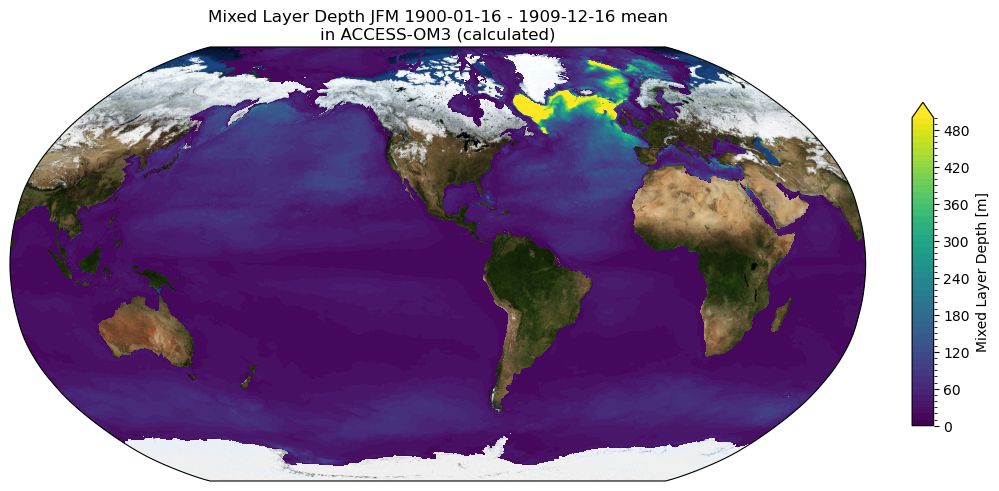

In [22]:
plot(model_JFM_mean,
    levels=51,
    vmin=0,
    vmax=500,
    extend="max",
    cmap='viridis',
    title=f"{mld_model_window.attrs['long_name']} JFM "
          f"{mld_model_window.time.values[0].strftime('%Y-%m-%d')} - "
          f"{mld_model_window.time.values[-1].strftime('%Y-%m-%d')} mean\nin {model_name} (calculated)"
    )


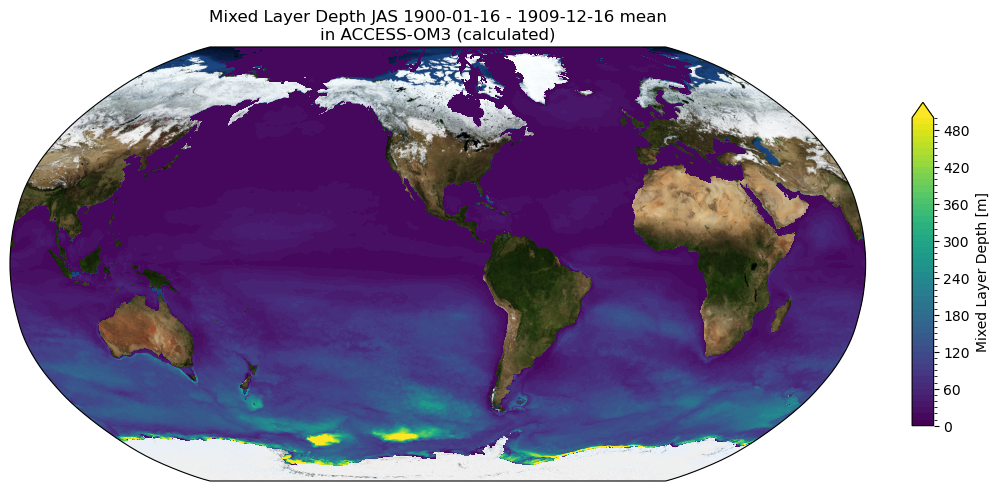

In [23]:
plot(model_JAS_mean,
    levels=51,
    vmin=0,
    vmax=500,
    extend="max",
    cmap='viridis',
    title=f"{mld_model_window.attrs['long_name']} JAS "
          f"{mld_model_window.time.values[0].strftime('%Y-%m-%d')} - "
          f"{mld_model_window.time.values[-1].strftime('%Y-%m-%d')} mean\nin {model_name} (calculated)"
     )


In [24]:
# TODO: append copy of westernmost data to eastern end to avoid gap in plot
# (same caveat noted in MLD.ipynb — DeBoyerMontegut obs has a longitude seam)

# DeBoyerMontegut is a 12-month climatology, so JFM/JAS means are a simple
# unweighted mean over the relevant 3 climatological months, not a
# days-in-month-weighted mean over many years like the model side above
obs_JFM_mean = obs_mld.isel(time=[0, 1, 2]).mean('time').load()
obs_JAS_mean = obs_mld.isel(time=[6, 7, 8]).mean('time').load()

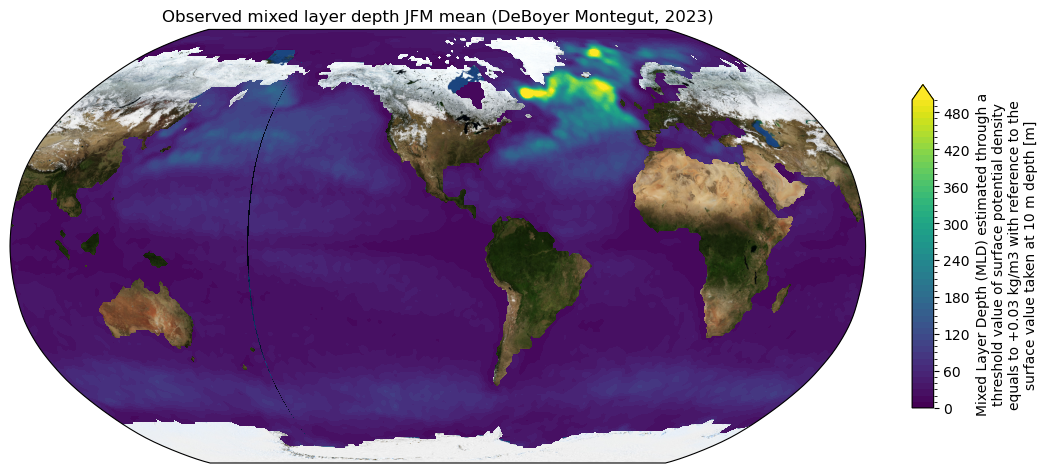

In [25]:
plot(obs_JFM_mean,
    levels=51,
    vmin=0,
    vmax=500,
    extend="max",
    cmap='viridis',
    title="Observed mixed layer depth JFM mean (DeBoyer Montegut, 2023)"
    )


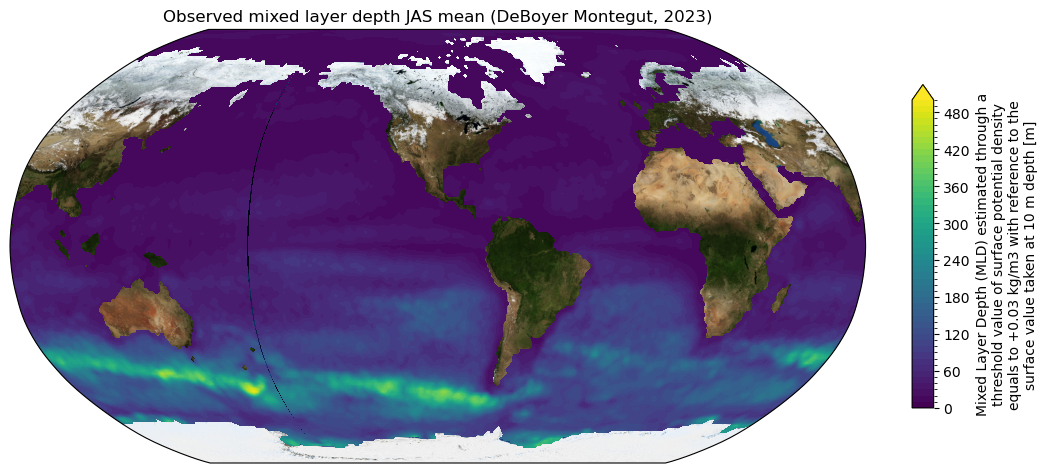

In [26]:
plot(obs_JAS_mean,
    levels=51,
    vmin=0,
    vmax=500,
    extend="max",
    cmap='viridis',
    title="Observed mixed layer depth JAS mean (DeBoyer Montegut, 2023)"
    )


### Side-by-side comparison: model vs observations

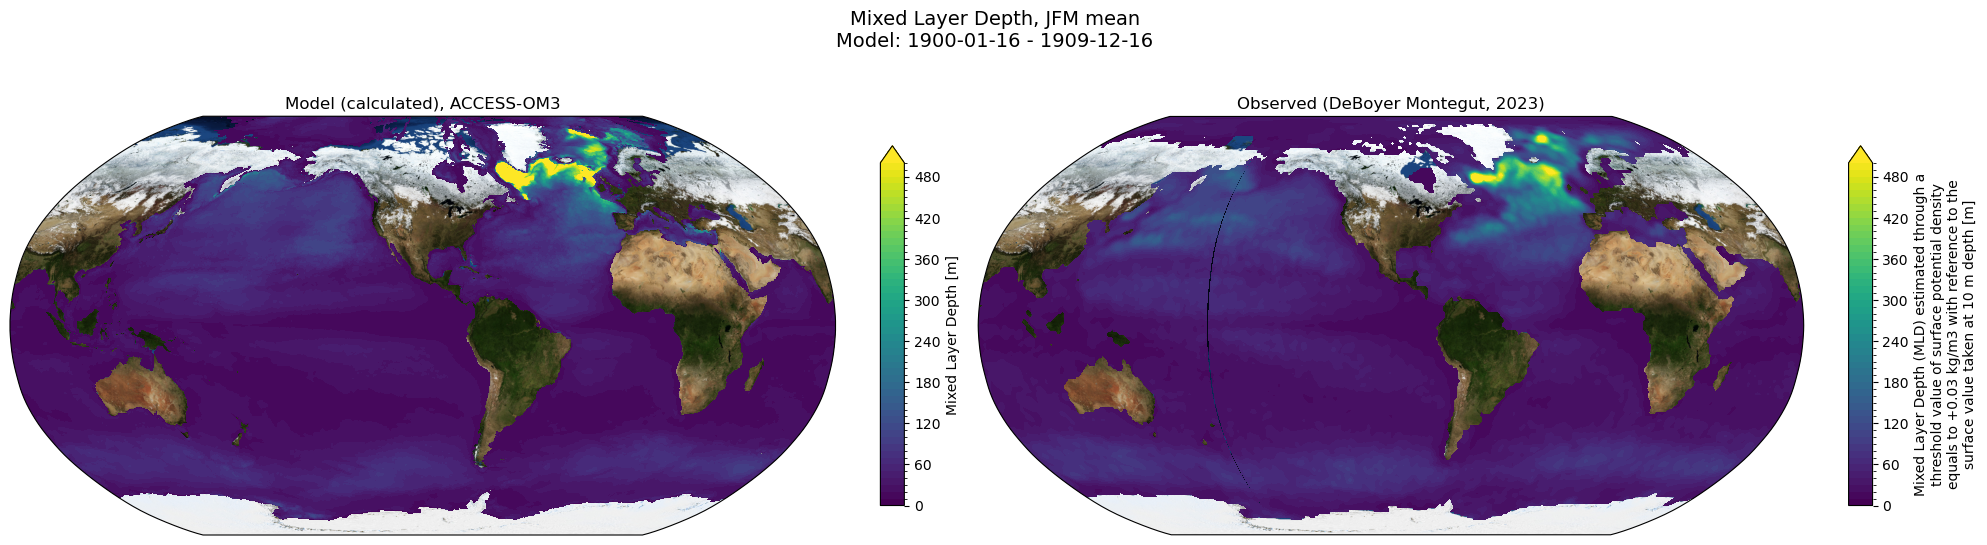

In [27]:
# Two-panel figure: model (left) and obs (right), sharing a Robinson projection
# and the same colour scale/levels, so the maps are directly comparable by eye
fig, (ax_model, ax_obs) = plt.subplots(
    1, 2, figsize=(20, 6),
    subplot_kw={"projection": ccrs.Robinson(central_longitude=-100)}
)

plot(model_JFM_mean,
     ax=ax_model,
     levels=51, vmin=0, vmax=500, extend="max", cmap='viridis',
     title=f"Model (calculated), {model_name}")

plot(obs_JFM_mean,
     ax=ax_obs,
     levels=51, vmin=0, vmax=500, extend="max", cmap='viridis',
     title="Observed (DeBoyer Montegut, 2023)")

fig.suptitle(
    f"Mixed Layer Depth, JFM mean\n"
    f"Model: {mld_model_window.time.values[0].strftime('%Y-%m-%d')} - "
    f"{mld_model_window.time.values[-1].strftime('%Y-%m-%d')}",
    fontsize=14
)
plt.tight_layout()

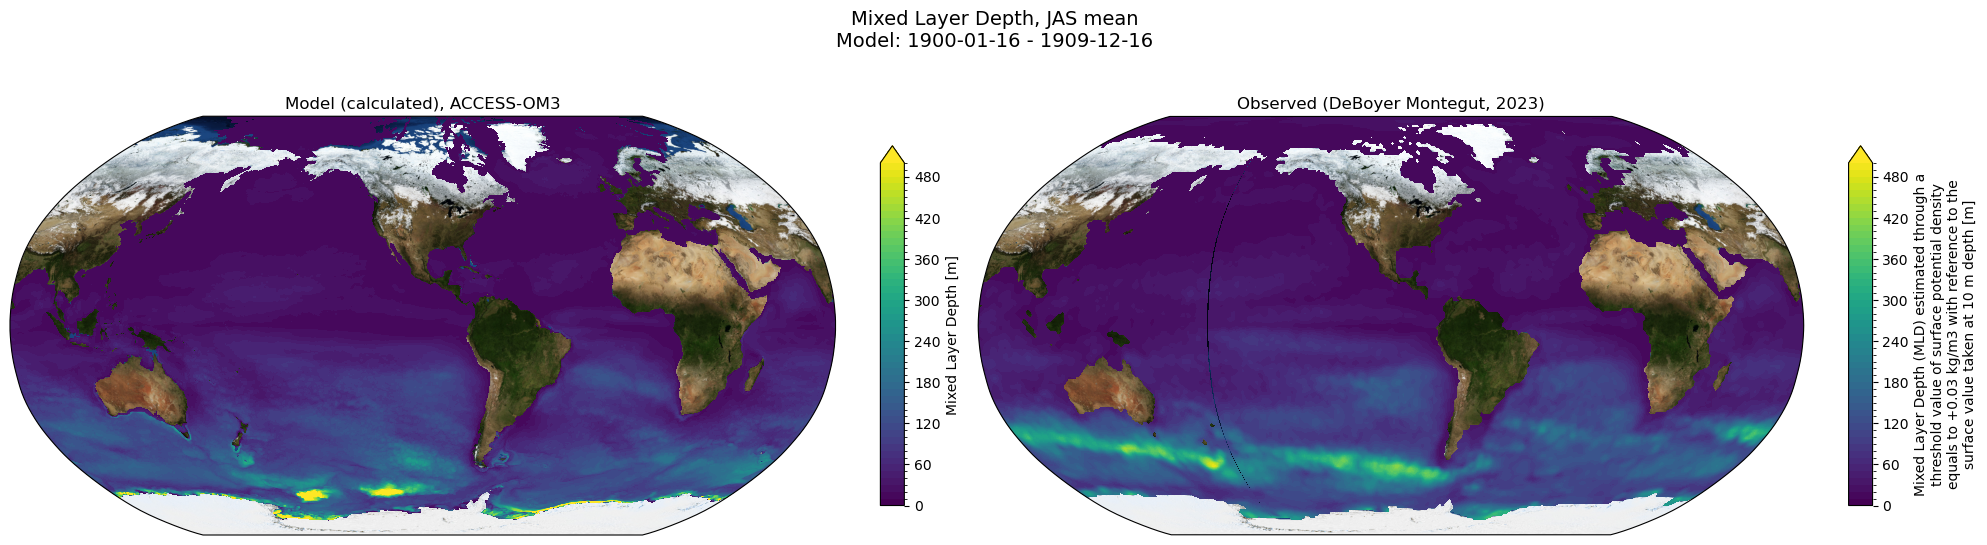

In [28]:
fig, (ax_model, ax_obs) = plt.subplots(
    1, 2, figsize=(20, 6),
    subplot_kw={"projection": ccrs.Robinson(central_longitude=-100)}
)

plot(model_JAS_mean,
     ax=ax_model,
     levels=51, vmin=0, vmax=500, extend="max", cmap='viridis',
     title=f"Model (calculated), {model_name}")

plot(obs_JAS_mean,
     ax=ax_obs,
     levels=51, vmin=0, vmax=500, extend="max", cmap='viridis',
     title="Observed (DeBoyer Montegut, 2023)")

fig.suptitle(
    f"Mixed Layer Depth, JAS mean\n"
    f"Model: {mld_model_window.time.values[0].strftime('%Y-%m-%d')} - "
    f"{mld_model_window.time.values[-1].strftime('%Y-%m-%d')}",
    fontsize=14
)
plt.tight_layout()

# Anomaly between Obs and OM3

In [29]:
from scipy.interpolate import interp1d
import cartopy.feature as cfeature

In [30]:
# Creating new spatial plot to look nice with anomalies
def plot_anomaly(dat, title=None, ax=None, **kwargs):
    """
    Plot a single 2D lon/lat field on a Robinson projection with land shown
    as light grey with a black coastline, matching the style used throughout
    MLD.ipynb.
    If `ax` is not supplied, a new figure+axes is created (single-panel case).
    If `ax` is supplied, it must already be a GeoAxes with a Robinson projection
    (this is what lets us reuse this function for the side-by-side panels below).
    """
    if title is None:
        title = dat.attrs.get('long_name', dat.name)
    created_fig = False
    if ax is None:
        fig = plt.figure(figsize=(12, 6))
        ax = plt.axes(projection=ccrs.Robinson(central_longitude=-100))
        created_fig = True
    # contourf the MLD field itself, transforming from plain lon/lat into the
    # Robinson projection on the fly
    cf = dat.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        cbar_kwargs={"label": "\n".join(wrap(f"{dat.attrs.get('long_name', dat.name)} [{dat.attrs.get('units', '')}]", 45)),
                     "fraction": 0.03, "aspect": 15, "shrink": 0.7},
        **kwargs
    )
    # Add light grey land fill with a black coastline on top, so land shows
    # through where MLD is NaN
    ax.add_feature(cfeature.LAND, zorder=1, facecolor="lightgrey")
    ax.add_feature(cfeature.COASTLINE, zorder=2, edgecolor="black", linewidth=0.8)
    ax.set_title(title)
    return cf

In [31]:
# Renaming coordinates to match obs
model_JFM_mean_new = model_JFM_mean.rename({'xh': 'lon', 'yh': 'lat'})
model_JAS_mean_new = model_JAS_mean.rename({'xh': 'lon', 'yh': 'lat'})

# Convert model longitude to [-180, 180]
model_JFM_mean_new = model_JFM_mean_new.assign_coords(lon=((model_JFM_mean_new.lon + 180) % 360) - 180)
model_JAS_mean_new = model_JAS_mean_new.assign_coords(lon=((model_JAS_mean_new.lon + 180) % 360) - 180)

# Sort after wrapping (important for interp)
model_JFM_mean_new = model_JFM_mean_new.sortby('lon')
model_JAS_mean_new = model_JAS_mean_new.sortby('lon')

# Interpolate
model_JFM_mean_interp = model_JFM_mean_new.interp(lat=obs_JFM_mean.lat, lon=obs_JFM_mean.lon)
model_JAS_mean_interp = model_JAS_mean_new.interp(lat=obs_JAS_mean.lat, lon=obs_JAS_mean.lon)

In [32]:
anomaly_JFM = model_JFM_mean_interp - obs_JFM_mean
anomaly_JAS = model_JAS_mean_interp - obs_JAS_mean

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/MLD_manual_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/MLD_manual.md


Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/MLD_manual.md successfully.


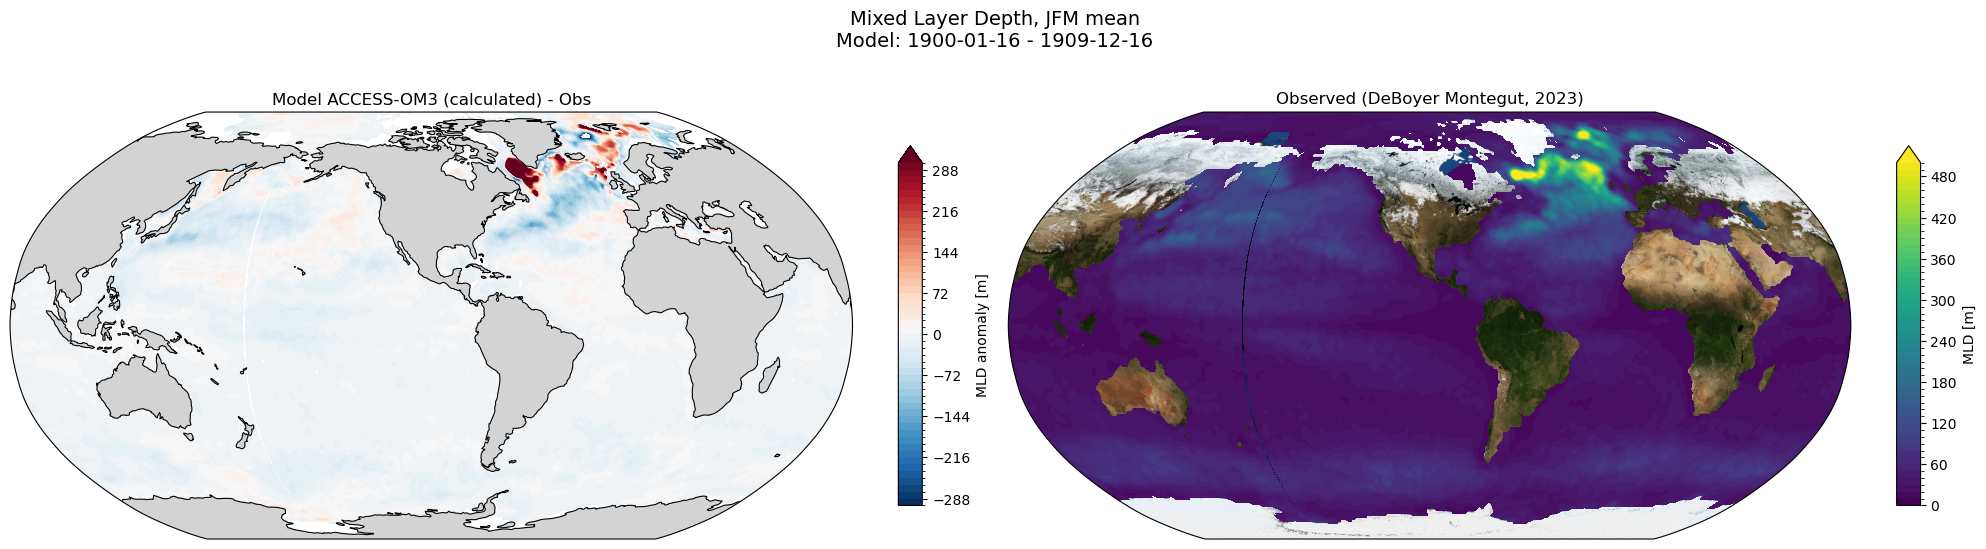

In [33]:
# Two-panel figure: model (left) and obs (right), sharing a Robinson projection
# and the same colour scale/levels, so the maps are directly comparable by eye
fig, (ax_model, ax_obs) = plt.subplots(
    1, 2, figsize=(20, 6),
    subplot_kw={"projection": ccrs.Robinson(central_longitude=-100)}
)

cf_model = plot_anomaly(anomaly_JFM,
     ax=ax_model,
     levels=51, vmin=-300, vmax=300, extend="max", cmap='RdBu_r',
     title=f"Model {model_name} (calculated) - Obs")
cf_model.colorbar.set_label("MLD anomaly [m]")

cf_obs = plot(obs_JFM_mean,
     ax=ax_obs,
     levels=51, vmin=0, vmax=500, extend="max", cmap='viridis',
     title="Observed (DeBoyer Montegut, 2023)")
cf_obs.colorbar.set_label("MLD [m]")

fig.suptitle(
    f"Mixed Layer Depth, JFM mean\n"
    f"Model: {mld_model_window.time.values[0].strftime('%Y-%m-%d')} - "
    f"{mld_model_window.time.values[-1].strftime('%Y-%m-%d')}",
    fontsize=14
)
plt.tight_layout()

mkmd.savefig(fig, "Mixed Layer Depth: Manual Model Anomaly vs Observed JFM (side by side)",
             "Side-by-side comparison of manually calculated model MLD anomaly and DeBoyer Montegut (2023) "
             "observed MLD, JFM mean. GitHub issue: "
             "[#38](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/38)")

Saved /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/MLD_manual_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/MLD_manual.md
Lines appended to /g/data/tm70/cyb561/repos/access-om3-paper-1-fixes/notebooks/mkfigs_output_FULL8-4/mkmd/MLD_manual.md successfully.


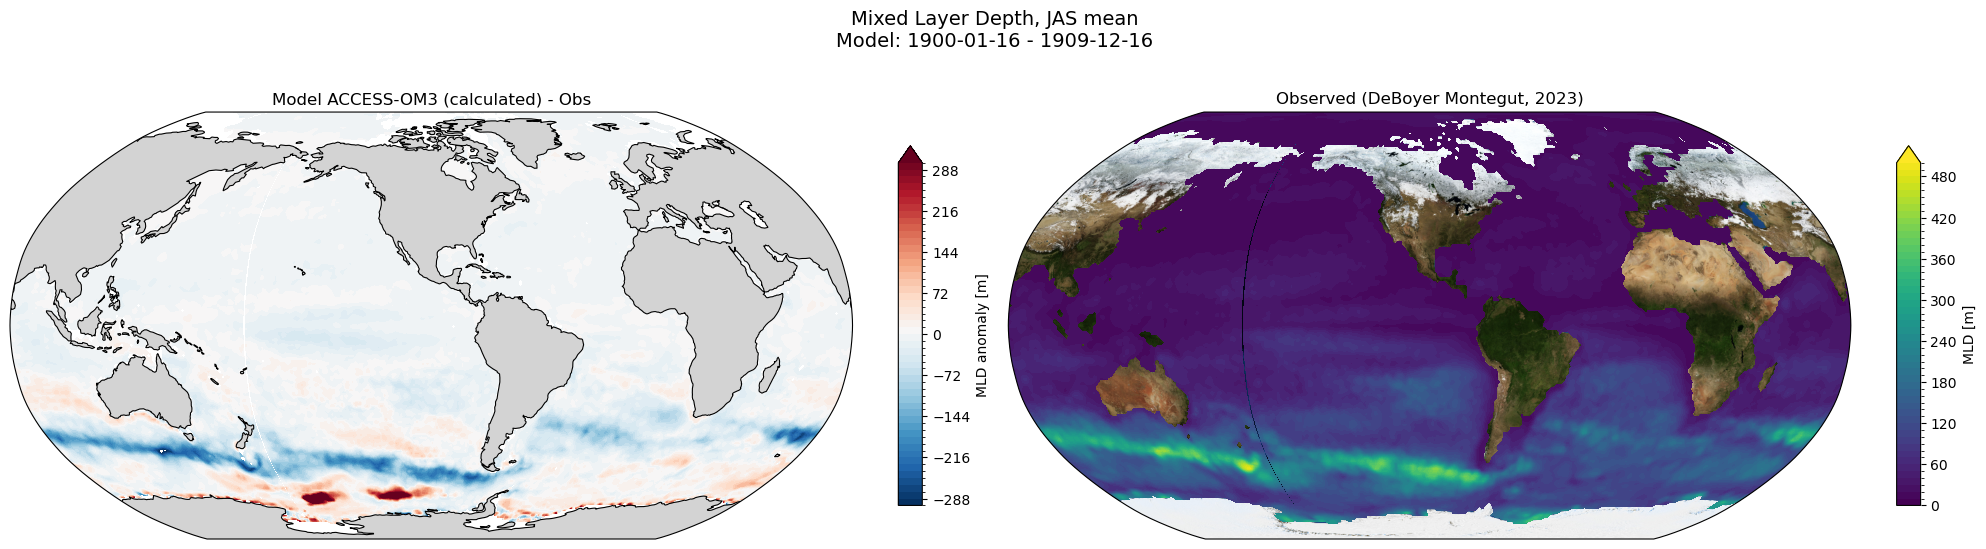

In [34]:
# Two-panel figure: model (left) and obs (right), sharing a Robinson projection
# and the same colour scale/levels, so the maps are directly comparable by eye
fig, (ax_model, ax_obs) = plt.subplots(
    1, 2, figsize=(20, 6),
    subplot_kw={"projection": ccrs.Robinson(central_longitude=-100)}
)

cf_model = plot_anomaly(anomaly_JAS,
     ax=ax_model,
     levels=51, vmin=-300, vmax=300, extend="max", cmap='RdBu_r',
     title=f"Model {model_name} (calculated) - Obs")
cf_model.colorbar.set_label("MLD anomaly [m]")

cf_obs = plot(obs_JAS_mean,
     ax=ax_obs,
     levels=51, vmin=0, vmax=500, extend="max", cmap='viridis',
     title="Observed (DeBoyer Montegut, 2023)")
cf_obs.colorbar.set_label("MLD [m]")

fig.suptitle(
    f"Mixed Layer Depth, JAS mean\n"
    f"Model: {mld_model_window.time.values[0].strftime('%Y-%m-%d')} - "
    f"{mld_model_window.time.values[-1].strftime('%Y-%m-%d')}",
    fontsize=14
)
plt.tight_layout()

mkmd.savefig(fig, "Mixed Layer Depth: Manual Model Anomaly vs Observed JAS (side by side)",
             "Side-by-side comparison of manually calculated model MLD anomaly and DeBoyer Montegut (2023) "
             "observed MLD, JAS mean. GitHub issue: "
             "[#38](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/38)")